In [1]:
import kagglehub
import pandas as pd
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer, PorterStemmer
import string
from nltk.tokenize import word_tokenize,sent_tokenize
from wordcloud import WordCloud
import matplotlib.pyplot as plt
import re
import seaborn as sns
from wordcloud import STOPWORDS

c:\Users\asus\Desktop\nlp\spam_detection\nlp_spam_detect\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
#variables i will need
lem=WordNetLemmatizer()
port=PorterStemmer()

In [3]:

# Download latest version
df=pd.read_csv("email_spam_indo.csv",usecols=['Kategori','Pesan'])
print(df.shape)
df.head(10)


(2636, 2)


,Kategori,Pesan
0,spam,Secara alami tak tertahankan identitas perusah...
1,spam,Fanny Gunslinger Perdagangan Saham adalah Merr...
2,spam,Rumah -rumah baru yang luar biasa menjadi muda...
3,spam,4 Permintaan Khusus Pencetakan Warna Informasi...
4,spam,"Jangan punya uang, dapatkan CD perangkat lunak..."
5,spam,"Nnews yang hebat halo, selamat datang di medzo..."
6,spam,Berikut ini adalah permainan panas di Investme...
7,spam,Simpan uang Anda beli untuk mendapatkan barang...
8,spam,Tidak Terkirim: Bisnis Berbasis Rumah Untuk Or...
9,spam,Simpan uang Anda beli untuk mendapatkan barang...


In [4]:
#check how many of each category, plot pie chart
print(df.describe())

       Kategori                                              Pesan
count      2636                                               2636
unique        2                                               2620
top        spam  Manoj Gupta - Jadwal Wawancara Terlampir Anda ...
freq       1368                                                  2


In [5]:
print(df.dropna())

     Kategori                                              Pesan
0        spam  Secara alami tak tertahankan identitas perusah...
1        spam  Fanny Gunslinger Perdagangan Saham adalah Merr...
2        spam  Rumah -rumah baru yang luar biasa menjadi muda...
3        spam  4 Permintaan Khusus Pencetakan Warna Informasi...
4        spam  Jangan punya uang, dapatkan CD perangkat lunak...
...       ...                                                ...
2631      ham  Pengingat halo semuanya: Vince telah meminta s...
2632      ham  Re: Argentina Power & Gas Market Modeling Oke ...
2633      ham  Re: Program Enron / Stanford Stinson, hebat! S...
2634      ham  Persetujuan untuk peninjau Roberts JR, Michael...
2635      ham  Re: Seminar Bollerslev sangat bagus. Terima ka...

[2636 rows x 2 columns]


finding: no missing values, no duplicate values

In [6]:
val_counts=df['Kategori'].value_counts()
val_counts


Kategori
spam    1368
ham     1268
Name: count, dtype: int64

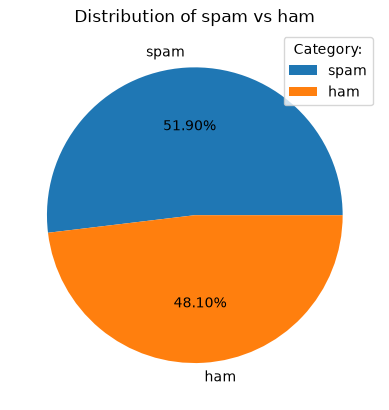

In [7]:
#plot pie chart of distribution
plt.pie(
    x=val_counts,
    labels=val_counts.index,
    autopct='%.2f%%'
    )
plt.legend(title = "Category:")
plt.title('Distribution of spam vs ham')
plt.show()

findings: more spam than ham in this dataset

# EDA: Character, word and sentence count


In [8]:
length=len(df['Pesan'][0])
print(f"Length of sample review: {length}")

Length of sample review: 1504


In [9]:
data=df
data['length']=data['Pesan'].str.len()
data.head(10)

,Kategori,Pesan,length
0,spam,Secara alami tak tertahankan identitas perusah...,1504
1,spam,Fanny Gunslinger Perdagangan Saham adalah Merr...,559
2,spam,Rumah -rumah baru yang luar biasa menjadi muda...,484
3,spam,4 Permintaan Khusus Pencetakan Warna Informasi...,504
4,spam,"Jangan punya uang, dapatkan CD perangkat lunak...",251
5,spam,"Nnews yang hebat halo, selamat datang di medzo...",495
6,spam,Berikut ini adalah permainan panas di Investme...,9545
7,spam,Simpan uang Anda beli untuk mendapatkan barang...,492
8,spam,Tidak Terkirim: Bisnis Berbasis Rumah Untuk Or...,477
9,spam,Simpan uang Anda beli untuk mendapatkan barang...,501


In [10]:
word_count=data['Pesan'][0].split()
print(f'Word count in a sample review: {len(word_count)}')

Word count in a sample review: 296


In [11]:
def word_count(pesan):
    pesan_list=pesan.split()
    return len(pesan_list)

In [12]:
data['Word_count']=data['Pesan'].apply(word_count)
data.head(10)

,Kategori,Pesan,length,Word_count
0,spam,Secara alami tak tertahankan identitas perusah...,1504,296
1,spam,Fanny Gunslinger Perdagangan Saham adalah Merr...,559,81
2,spam,Rumah -rumah baru yang luar biasa menjadi muda...,484,75
3,spam,4 Permintaan Khusus Pencetakan Warna Informasi...,504,85
4,spam,"Jangan punya uang, dapatkan CD perangkat lunak...",251,37
5,spam,"Nnews yang hebat halo, selamat datang di medzo...",495,80
6,spam,Berikut ini adalah permainan panas di Investme...,9545,1391
7,spam,Simpan uang Anda beli untuk mendapatkan barang...,492,76
8,spam,Tidak Terkirim: Bisnis Berbasis Rumah Untuk Or...,477,93
9,spam,Simpan uang Anda beli untuk mendapatkan barang...,501,76


In [13]:
import numpy as np
data['mean_word_length']=data['Pesan'].map(lambda rev: np.mean ([len(word) for word in rev.split()]))
data.head(10)

,Kategori,Pesan,length,Word_count,mean_word_length
0,spam,Secara alami tak tertahankan identitas perusah...,1504,296,4.084459
1,spam,Fanny Gunslinger Perdagangan Saham adalah Merr...,559,81,5.913580
2,spam,Rumah -rumah baru yang luar biasa menjadi muda...,484,75,5.466667
3,spam,4 Permintaan Khusus Pencetakan Warna Informasi...,504,85,4.941176
4,spam,"Jangan punya uang, dapatkan CD perangkat lunak...",251,37,5.810811
5,spam,"Nnews yang hebat halo, selamat datang di medzo...",495,80,5.200000
6,spam,Berikut ini adalah permainan panas di Investme...,9545,1391,5.862689
7,spam,Simpan uang Anda beli untuk mendapatkan barang...,492,76,5.486842
8,spam,Tidak Terkirim: Bisnis Berbasis Rumah Untuk Or...,477,93,4.139785
9,spam,Simpan uang Anda beli untuk mendapatkan barang...,501,76,5.605263


In [14]:
#average length of sentences in review
np.mean([len(sent)for sent in sent_tokenize(data['Pesan'][0])])

np.float64(135.8181818181818)

In [15]:
data['mean_sent_length']=data['Pesan'].map(
    lambda rev:
    np.mean([len(sent)for sent in sent_tokenize(rev)])
)
data.head(3)

,Kategori,Pesan,length,Word_count,mean_word_length,mean_sent_length
0,spam,Secara alami tak tertahankan identitas perusah...,1504,296,4.084459,135.818182
1,spam,Fanny Gunslinger Perdagangan Saham adalah Merr...,559,81,5.913580,279.000000
2,spam,Rumah -rumah baru yang luar biasa menjadi muda...,484,75,5.466667,120.250000


In [16]:
def visualize(col):
    plt.subplot(1,2,1)
    sns.boxplot(y=data[col], hue=data['Kategori'])
    plt.ylabel(col, labelpad=12.5)
    
    plt.subplot(1,2,2)
    sns.kdeplot(data=data, x=col, hue='Kategori')
    plt.legend(data['Kategori'].unique())
    plt.xlabel('')
    plt.ylabel('')
    
    plt.show()

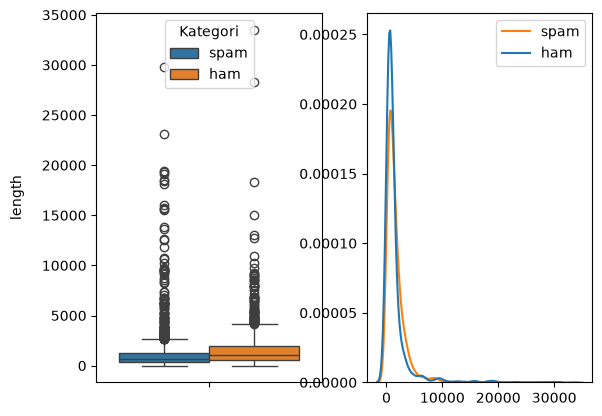

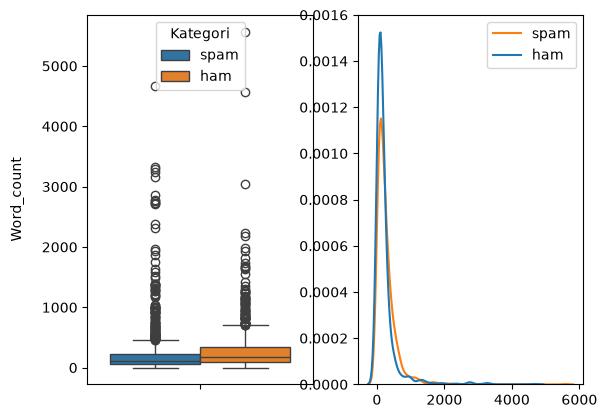

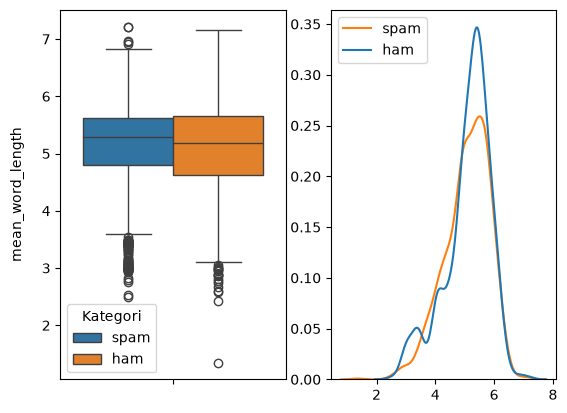

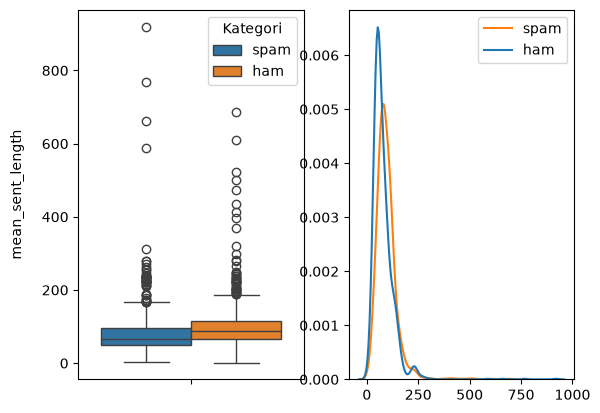

In [17]:
features = data.columns.tolist()[2:]
for feature in features:
    visualize(feature)

In [18]:
#examine emails length, vocab size
email_length=df['Pesan'].str.len()
print('Email Length Summary')
email_length.describe()

Email Length Summary


count     2636.000000
mean      1481.520106
std       2215.573869
min          3.000000
25%        446.000000
50%        860.000000
75%       1626.000000
max      33531.000000
Name: Pesan, dtype: float64

In [19]:
#by category
spam_cat=df[df['Kategori']=='spam']
ham_cat=df[df['Kategori']=='ham']

spam_length=spam_cat['Pesan'].str.len()
ham_length=ham_cat['Pesan'].str.len()
spam_length.describe()

count     1368.000000
mean      1351.805556
std       2343.474611
min          6.000000
25%        395.000000
50%        707.000000
75%       1297.500000
max      29757.000000
Name: Pesan, dtype: float64

In [20]:
ham_length.describe()

count     1268.000000
mean      1621.464511
std       2060.520957
min          3.000000
25%        531.750000
50%       1090.000000
75%       1981.000000
max      33531.000000
Name: Pesan, dtype: float64

In [21]:
#correlation matrix of length on
df_length=df[['Kategori']]
df_length['Kategori']=df_length['Kategori']=='ham'
df_length['Length']=df['Pesan'].str.len()
df_length.head()

,Kategori,Length
0,False,1504
1,False,559
2,False,484
3,False,504
4,False,251


          Kategori    Length
Kategori  1.000000  0.060823
Length    0.060823  1.000000


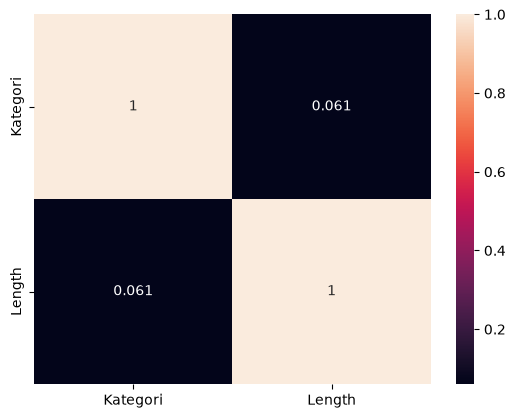

In [22]:
import seaborn as sns
df_length_corr=df_length.corr()
print(df_length_corr)
ax = sns.heatmap(df_length_corr, annot=True)

finding: extremely weak correlation between length and spam

Vocabulary size

In [23]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2636 entries, 0 to 2635
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Kategori          2636 non-null   str    
 1   Pesan             2636 non-null   str    
 2   length            2636 non-null   int64  
 3   Word_count        2636 non-null   int64  
 4   mean_word_length  2636 non-null   float64
 5   mean_sent_length  2636 non-null   float64
dtypes: float64(2), int64(2), str(2)
memory usage: 123.7 KB


In [24]:
def returnStopwords(addNER):
    ind_stopwords=stopwords.words("indonesian")
    stopwords = set(ind_stopwords)

    if(addNER<=0):
        banned_words=stopwords.words('english')
    else:
        specific_words={'enron','ect','cc','kaminski','vince','j'}
        banned_words=stopwords.union(specific_words)
        
    return banned_words

In [ ]:
def clean(pesan):
    #lowercase
    pesan=pesan.lower()
    
    #remove punct
    pesan = re.sub('[^a-z A-Z 0-9-]+', '', pesan)

    #remove stopwords
    pesan = " ".join([word for word in pesan.split() if word not in stopwords.words('indonesian')])
    return pesan

In [ ]:
df['PesanClean'] = df['Pesan'].apply(clean)

df.head(10)

,Kategori,Pesan,length,Word_count,mean_word_length,mean_sent_length,PesanClean
0,spam,Secara alami tak tertahankan identitas perusah...,1504,296,4.084459,135.818182,alami tertahankan identitas perusahaan sulit p...
1,spam,Fanny Gunslinger Perdagangan Saham adalah Merr...,559,81,5.913580,279.000000,fanny gunslinger perdagangan saham merrill muz...
2,spam,Rumah -rumah baru yang luar biasa menjadi muda...,484,75,5.466667,120.250000,rumah -rumah mudah pemilik rumah disetujui pin...
3,spam,4 Permintaan Khusus Pencetakan Warna Informasi...,504,85,4.941176,100.000000,4 permintaan khusus pencetakan warna informasi...
4,spam,"Jangan punya uang, dapatkan CD perangkat lunak...",251,37,5.810811,27.000000,uang dapatkan cd perangkat lunak kompatibilita...
5,spam,"Nnews yang hebat halo, selamat datang di medzo...",495,80,5.200000,164.333333,nnews hebat halo selamat medzonline sh grounds...
6,spam,Berikut ini adalah permainan panas di Investme...,9545,1391,5.862689,141.477612,permainan panas investments security investmen...
7,spam,Simpan uang Anda beli untuk mendapatkan barang...,492,76,5.486842,53.777778,simpan uang beli barang mencoba ciall membayan...
8,spam,Tidak Terkirim: Bisnis Berbasis Rumah Untuk Or...,477,93,4.139785,158.333333,terkirim bisnis berbasis rumah orang tata subj...
9,spam,Simpan uang Anda beli untuk mendapatkan barang...,501,76,5.605263,54.777778,simpan uang beli barang mencoba ciall membayan...


In [39]:
def corpus(text):
    text_list = text.split()
    return text_list

In [41]:
df['Pesan_lists'] = df['PesanClean'].apply(corpus)
df.head(10)

,Kategori,Pesan,length,Word_count,mean_word_length,mean_sent_length,PesanClean,Pesan_lists
0,spam,Secara alami tak tertahankan identitas perusah...,1504,296,4.084459,135.818182,alami tertahankan identitas perusahaan sulit p...,"[alami, tertahankan, identitas, perusahaan, su..."
1,spam,Fanny Gunslinger Perdagangan Saham adalah Merr...,559,81,5.913580,279.000000,fanny gunslinger perdagangan saham merrill muz...,"[fanny, gunslinger, perdagangan, saham, merril..."
2,spam,Rumah -rumah baru yang luar biasa menjadi muda...,484,75,5.466667,120.250000,rumah -rumah mudah pemilik rumah disetujui pin...,"[rumah, -rumah, mudah, pemilik, rumah, disetuj..."
3,spam,4 Permintaan Khusus Pencetakan Warna Informasi...,504,85,4.941176,100.000000,4 permintaan khusus pencetakan warna informasi...,"[4, permintaan, khusus, pencetakan, warna, inf..."
4,spam,"Jangan punya uang, dapatkan CD perangkat lunak...",251,37,5.810811,27.000000,uang dapatkan cd perangkat lunak kompatibilita...,"[uang, dapatkan, cd, perangkat, lunak, kompati..."
5,spam,"Nnews yang hebat halo, selamat datang di medzo...",495,80,5.200000,164.333333,nnews hebat halo selamat medzonline sh grounds...,"[nnews, hebat, halo, selamat, medzonline, sh, ..."
6,spam,Berikut ini adalah permainan panas di Investme...,9545,1391,5.862689,141.477612,permainan panas investments security investmen...,"[permainan, panas, investments, security, inve..."
7,spam,Simpan uang Anda beli untuk mendapatkan barang...,492,76,5.486842,53.777778,simpan uang beli barang mencoba ciall membayan...,"[simpan, uang, beli, barang, mencoba, ciall, m..."
8,spam,Tidak Terkirim: Bisnis Berbasis Rumah Untuk Or...,477,93,4.139785,158.333333,terkirim bisnis berbasis rumah orang tata subj...,"[terkirim, bisnis, berbasis, rumah, orang, tat..."
9,spam,Simpan uang Anda beli untuk mendapatkan barang...,501,76,5.605263,54.777778,simpan uang beli barang mencoba ciall membayan...,"[simpan, uang, beli, barang, mencoba, ciall, m..."


In [42]:
corpus = []
from tqdm import trange
for i in trange(df.shape[0], ncols=150, nrows=10, colour='green', smoothing=0.8):
    corpus += df['Pesan_lists'][i]
len(corpus)

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████| 2636/2636 [00:00<00:00, 87056.58it/s]


371115

In [43]:
from collections import Counter
mostCommon = Counter(corpus).most_common(10)
mostCommon

[('-', 38341),
 ('enron', 3499),
 ('ect', 2957),
 ('vince', 2410),
 ('com', 2193),
 ('perusahaan', 1639),
 ('memiliki', 1545),
 ('1', 1476),
 ('hou', 1472),
 ('kaminski', 1328)]

In [44]:
words = []
freq = []
for word, count in mostCommon:
    words.append(word)
    freq.append(count)

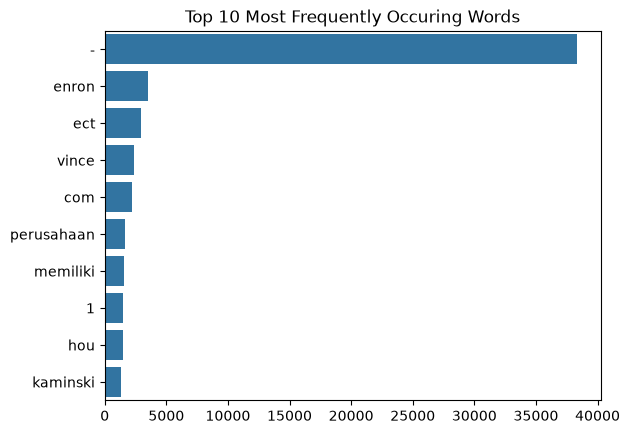

In [45]:
sns.barplot(x=freq, y=words)
plt.title('Top 10 Most Frequently Occuring Words')
plt.show()

In [27]:
#analyze vocabulary size

def analyzeVocabSize(dataframe):
    text = ' '.join(dataframe['Pesan'].astype(str).tolist())

    text = re.sub(r'[^A-Za-z\s]', '', text)

    text = text.lower()
    # specific_words={'enron','ect','cc','kaminski','vince','j'}
    # banned_words=stopwords.union(specific_words)
    banned_words=stopwords
    text = ' '.join(word for word in text.split() if word not in banned_words)
    set_words = pd.Series(text.split()).value_counts().to_dict()
    print("Vocab list:")
    print(set_words)
    print("Vocab list:")
    print(len(set_words))
    return set_words


In [28]:
ind_stopwords=stopwords.words("indonesian")
stopwords = set(ind_stopwords)

In [29]:
print("Spam analysis")
spam_v=analyzeVocabSize(spam_cat)
print("Ham analysis")
ham_v=analyzeVocabSize(ham_cat)

Spam analysis
Vocab list:
{'perusahaan': 1198, 'com': 990, 'email': 939, 'situs': 937, 'bisnis': 790, 'informasi': 770, 'orang': 755, 'uang': 749, 'web': 710, 'memiliki': 702, 'http': 601, 'e': 578, 'menerima': 563, 'gratis': 557, 'pesan': 545, 'harga': 524, 'klik': 519, 'surat': 486, 'lunak': 483, 'laporan': 463, 'adobe': 462, 'alamat': 449, 'perangkat': 448, 'www': 424, 'a': 417, 'saham': 364, 'program': 357, 'daftar': 355, 'investasi': 355, 'layanan': 354, 'online': 347, 'nama': 346, 'negara': 330, 'pernyataan': 330, 'pelanggan': 326, 'akun': 323, 'produk': 316, 'silakan': 316, 'pasar': 311, 'rumah': 295, 'menghasilkan': 295, 'sistem': 288, 'penawaran': 286, 'biaya': 285, 'cepat': 283, 's': 277, 'internet': 277, 'terbaik': 271, 'mail': 259, 'iklan': 259, 'tersedia': 256, 'dunia': 255, 'membantu': 253, 'kirim': 251, 'logo': 243, 'khusus': 243, 'l': 243, 'salah': 242, 'juta': 242, 'pemasaran': 240, 'keamanan': 237, 'mudah': 234, 'teknologi': 233, 'r': 226, 'x': 225, 'industri': 221, '

In [30]:
#store to spam dict txt and ham dict txt
import json
with open("spam_dict.json", "w") as f:
  json.dump(spam_v,f)
f.close()
with open("ham_dict.json", "w") as f:
  json.dump(ham_v,f)
f.close()


named entites in ham dataset, namely Enron, Vincent "Vince" J. Kaminski, Shirley.

the word 'viagra' never shows up in ham rows while it shows up 173 times in spam
many spelling mistakes in spam_dict

In [31]:
def showCloud(dataframe):
    text = ' '.join(dataframe['Pesan'].astype(str).tolist())

    text = re.sub(r'[^A-Za-z\s]', '', text)

    text = text.lower()
    specific_words={'enron','ect','cc','kaminski','vince','ect','hou','shirley'}
    banned_words=stopwords.union(specific_words)
    text = ' '.join(word for word in text.split() if word not in banned_words)
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text)
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')  
    plt.title("Word Cloud")
    plt.show()

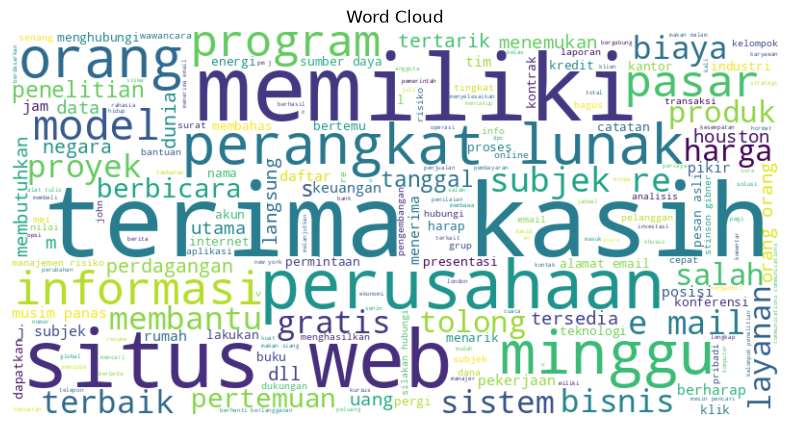

In [32]:
showCloud(df)

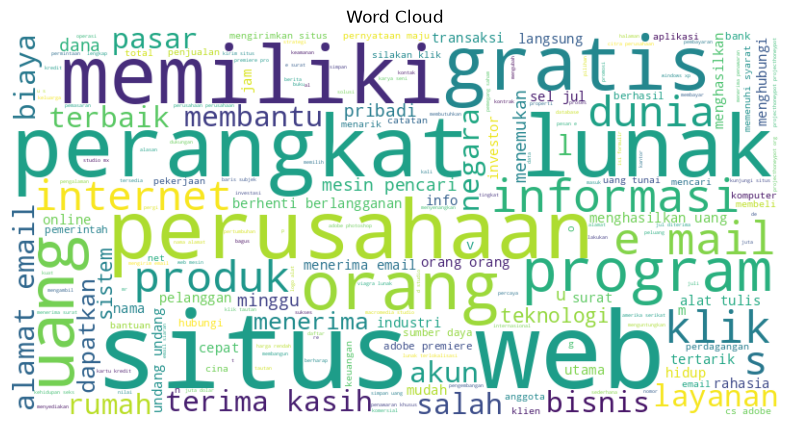

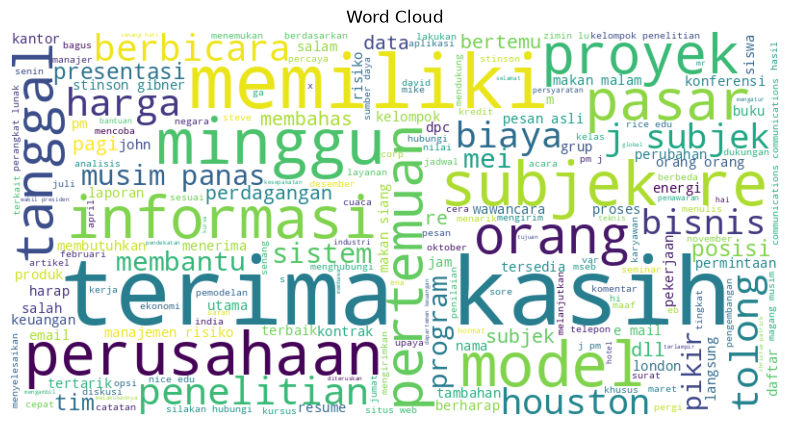

In [33]:
#repeat with spam and nonspam categories
#spam
spam_df = df[df['Kategori']=='spam']
showCloud(spam_df)

ham_df = df[df['Kategori']=='ham']
showCloud(ham_df)

In [34]:
#to do list: remove the name vince j kaminski, enron, shirley crenshaw

In [46]:
#n-gram analysis

from sklearn.feature_extraction.text import CountVectorizer
cv = CountVectorizer(ngram_range=(2,2))
bigrams = cv.fit_transform(df['PesanClean'])


In [47]:
count_values = bigrams.toarray().sum(axis=0)
ngram_freq = pd.DataFrame(sorted([(count_values[i], k) for k, i in cv.vocabulary_.items()], reverse = True))
ngram_freq.columns = ["frequency", "ngram"]

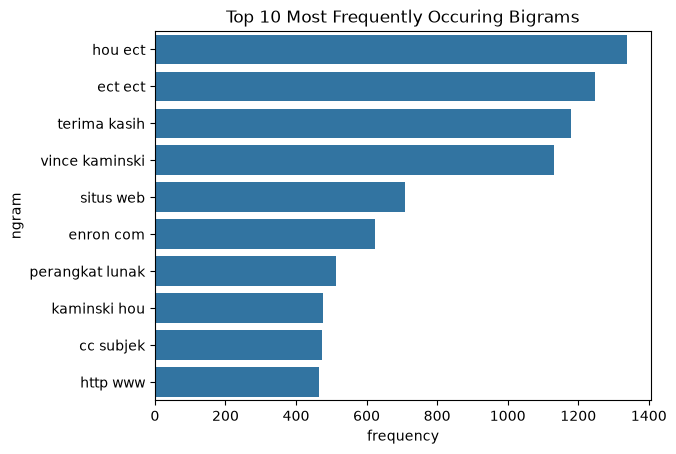

In [48]:
sns.barplot(x=ngram_freq['frequency'][:10], y=ngram_freq['ngram'][:10])
plt.title('Top 10 Most Frequently Occuring Bigrams')
plt.show()

In [50]:
cv1 = CountVectorizer(ngram_range=(3,3))
trigrams = cv1.fit_transform(df['PesanClean'])
count_values = trigrams.toarray().sum(axis=0)
ngram_freq = pd.DataFrame(sorted([(count_values[i], k) for k, i in cv1.vocabulary_.items()], reverse = True))
ngram_freq.columns = ["frequency", "ngram"]

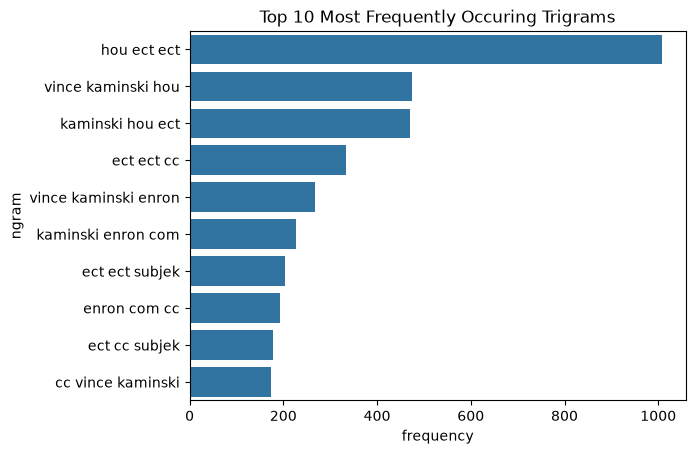

In [51]:
sns.barplot(x=ngram_freq['frequency'][:10], y=ngram_freq['ngram'][:10])
plt.title('Top 10 Most Frequently Occuring Trigrams')
plt.show()

In [36]:
#sentiment analysis

In [37]:
#part-of-speech-tagging

In [38]:
#topic modelling with Latent Dirichlet Allocation

Analyze the total number of emails and the distribution of spam versus legitimate emails. This is to adjust our strategy in case there is an imbalance in the dataset. After this we will examine the general length of emails and vocabulary size, check for missing values and remove duplicate emails. Frequency analysis of non-stopword words will be carried out and displayed via WordCloud. Other tasks that will be carried out include n-gram analysis, sentiment analysis, part-of-speech tagging and topic modelling using Latent Dirichlet Allocation. This will give us insight into what spam emails typically talk about vs ham emails, potentially revealing common techniques spam emails use to get users to click on them.
